## Setup

In [ ]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/3")
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
commercials = pd.read_parquet(f"{DATA}/commercials.parquet")
rate_card = pd.read_parquet(f"{DATA}/rate_card.parquet")

Using Colab cache for faster access to the 'adtech-lab1-tv-panel' dataset.


In [ ]:
print("viewings columns:", viewings.columns.tolist())
print("viewer_attributes columns:", viewer_attributes.columns.tolist())
print("daily_weights columns:", daily_weights.columns.tolist())
print("attributes columns:", attributes.columns.tolist())

viewings columns: ['viewing_id', 'respondent_id', 'resp_type', 'guest_attr_ids', 'network_code', 'start_ts', 'end_ts', 'playback', 'weight']
viewer_attributes columns: ['respondent_id', 'attr_id', 'value']
daily_weights columns: ['respondent_id', 'resp_type', 'broadcast_date', 'weight']
attributes columns: ['attr_id', 'attr_group', 'attr_name', 'value_type', 'applies_to']


In [ ]:
commercials['broadcast_dt'] = commercials['start_ts'] - pd.Timedelta(hours=6)
commercials['broadcast_date'] = commercials['broadcast_dt'].dt.date
commercials['broadcast_weekday'] = commercials['broadcast_dt'].dt.weekday
commercials['broadcast_minute'] = commercials['broadcast_dt'].dt.hour * 60 + commercials['broadcast_dt'].dt.minute

## Task 1.1 — Size

In [ ]:
print("Spots:", commercials['ad_airing_id'].nunique())
print("Pods:", commercials['pod_id'].nunique())
print("Brands:", commercials['brand'].nunique())
print("Categories:", commercials['category'].nunique())

brand_a_spots = commercials[commercials['brand'] == 'BRAND_A']
print("BRAND_A spots:", len(brand_a_spots))

Spots: 167720
Pods: 22359
Brands: 95
Categories: 14
BRAND_A spots: 300


In [ ]:
display(brand_a_spots.groupby('network_code').size().reset_index(name='spots_count'))

,network_code,spots_count
0,ABC,29
1,BRAVO,33
2,CBS,22
3,FNC,40
4,FOOD,33
5,FOX,13
6,FX,38
7,HGTV,39
8,HIST,37
9,NBC,16


## Task 1.2 — Ad load

In [ ]:
comm_load = commercials.copy()
comm_load['broadcast_hour'] = comm_load['broadcast_dt'].dt.floor('H')
ad_load = comm_load.groupby(['network_code', 'broadcast_hour'])['length_sec'].sum().reset_index()
ad_load['ad_minutes'] = ad_load['length_sec'] / 60
ad_load_avg = ad_load.groupby('network_code')['ad_minutes'].mean().reset_index().round(2)

/tmp/ipykernel_1128/3262880827.py:2: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  comm_load['broadcast_hour'] = comm_load['broadcast_dt'].dt.floor('H')


In [ ]:
display(ad_load_avg)
print("Heaviest ad load:", ad_load_avg.loc[ad_load_avg['ad_minutes'].idxmax()]['network_code'])

,network_code,ad_minutes
0,ABC,11.84
1,BRAVO,13.43
2,CBS,12.14
3,FNC,15.64
4,FOOD,13.11
5,FOX,11.79
6,FX,12.92
7,HGTV,13.34
8,HIST,13.21
9,NBC,11.82


Heaviest ad load: FNC


**Answer:** Broadcast networks (NBC, CBS, ABC, FOX) have hours without national ads because those ad breaks are sold locally by affiliate stations, or they belong to local news programming, paid programming, or special unrated events.

## Task 1.3 — Price everything

In [ ]:
comm_prog = commercials.merge(programs[['telecast_id', 'program_name']], on='telecast_id', how='left')

rc_prog = rate_card[rate_card['program_name'].notna() & (rate_card['program_name'] != '')].copy()
rc_time = rate_card[rate_card['program_name'].isna() | (rate_card['program_name'] == '')].copy()

matched_prog = comm_prog.merge(rc_prog[['network_code', 'program_name', 'daypart', 'cost_30s_usd']],
                               on=['network_code', 'program_name'], how='inner')

def parse_time(t):
    h, m = map(int, t.split(':'))
    return (h - 6) * 60 + m

rc_time['start_min'] = rc_time['start_time'].apply(parse_time)
rc_time['end_min'] = rc_time['end_time'].apply(parse_time)
rc_time = rc_time.explode('weekdays')
rc_time['weekdays'] = rc_time['weekdays'].astype(int)

unmatched_comm = comm_prog[~comm_prog['ad_airing_id'].isin(matched_prog['ad_airing_id'])]
matched_time = unmatched_comm.merge(rc_time, left_on=['network_code', 'broadcast_weekday'], right_on=['network_code', 'weekdays'])
matched_time = matched_time[(matched_time['broadcast_minute'] >= matched_time['start_min']) &
                            (matched_time['broadcast_minute'] < matched_time['end_min'])]

all_priced_spots = pd.concat([matched_prog, matched_time])

all_priced_spots['cost'] = all_priced_spots['cost_30s_usd'] * (all_priced_spots['length_sec'] / 30)

print("Spots without a price:", len(commercials) - len(all_priced_spots))

value_by_net = all_priced_spots.groupby('network_code')['cost'].sum().reset_index()
value_by_net['Total_Value_M'] = (value_by_net['cost'] / 1e6).round(2)

prog_value_by_net = all_priced_spots[all_priced_spots['program_name'].notna() & (all_priced_spots['program_name'] != '')].groupby('network_code')['cost'].sum().reset_index().rename(columns={'cost': 'prog_cost'})
value_summary = value_by_net.merge(prog_value_by_net, on='network_code', how='left').fillna(0)
value_summary['Prog_Share'] = (value_summary['prog_cost'] / value_summary['cost']).round(3)

display(value_summary[['network_code', 'Total_Value_M', 'Prog_Share']])

Spots without a price: 0


,network_code,Total_Value_M,Prog_Share
0,ABC,708.79,0.432
1,BRAVO,25.31,0.000
2,CBS,818.78,0.230
3,FNC,315.85,0.000
4,FOOD,42.15,0.000
5,FOX,696.17,0.835
6,FX,42.51,0.000
7,HGTV,58.10,0.000
8,HIST,40.09,0.000
9,NBC,724.32,0.342


## Task 2.1 — Delivery

In [ ]:
age_attr_ids = attributes[attributes['attr_name'].str.lower() == 'age']['attr_id'].tolist()

unique_ages = viewer_attributes[viewer_attributes['attr_id'].isin(age_attr_ids)]['value'].unique()

print("Всі доступні атрибути:")
print(attributes['attr_name'].unique())

Всі доступні атрибути:
['R: panel member (household member)' 'L: long-term visitor'
 'S: short-term visitor (guest); id ends 81, 82, ... = guest button, not a stable person'
 'H: household record (id ending 00)' 'Male' 'Female' 'Age in years' '2-5'
 '6-11' '12-17' '18-20' '21-24' '25-34' '35-49' '50-54' '55-64' '65+'
 'Hispanic' 'White, non-Hispanic' 'Black, non-Hispanic'
 'Asian, non-Hispanic' 'Other, non-Hispanic' 'Less than high school'
 'High school graduate' 'Some college / associate'
 "Bachelor's degree or higher" 'Working full time (30+ h/week)'
 'Working part time' 'Not working' 'Head of house' 'Lady of house'
 '1 person' '2 persons' '3 persons' '4 persons' '5+ persons' 'Under $25k'
 '$25k-$50k' '$50k-$75k' '$75k-$100k' '$100k-$150k' '$150k+'
 'Children under 18 present' 'No children under 18' 'Wired cable'
 'Satellite (DBS)' 'Telco / fiber' 'Virtual MVPD (e.g. YouTube TV)'
 'Broadcast only (antenna)' 'Broadband only (no pay TV, no antenna)'
 'Northeast' 'Midwest' 'South' 'West

In [ ]:
ba_spots = all_priced_spots[all_priced_spots['brand'] == 'BRAND_A'].copy()

viewings['start_ts'] = pd.to_datetime(viewings['start_ts'])
viewings['end_ts'] = pd.to_datetime(viewings['end_ts'])
viewings['broadcast_date'] = (viewings['start_ts'] - pd.Timedelta(hours=6)).dt.date

exposures = viewings.merge(ba_spots[['ad_airing_id', 'network_code', 'start_ts']],
                           on='network_code',
                           suffixes=('_view', '_ad'))

exposures = exposures[(exposures['start_ts_ad'] >= exposures['start_ts_view']) &
                      (exposures['start_ts_ad'] < exposures['end_ts'])]

valid_respondents = daily_weights[daily_weights['resp_type'].isin(['R', 'L'])]['respondent_id'].unique()
exposures = exposures[exposures['respondent_id'].isin(valid_respondents)]

exposures = exposures.merge(daily_weights[['respondent_id', 'broadcast_date']],
                            on=['respondent_id', 'broadcast_date'],
                            how='inner')

age_attr_ids = attributes[attributes['attr_name'].str.lower() == 'age']['attr_id'].tolist()

age_df = viewer_attributes[viewer_attributes['attr_id'].isin(age_attr_ids)].copy()
age_df['age_val'] = pd.to_numeric(age_df['value'], errors='coerce')

target_age_names = ['18-20', '21-24', '25-34', '35-49']

a18_49_attr_ids = attributes[attributes['attr_name'].isin(target_age_names)]['attr_id'].tolist()

a18_49_respondents = viewer_attributes[
    viewer_attributes['attr_id'].isin(a18_49_attr_ids)
]['respondent_id'].unique()

monthly_weights = daily_weights[daily_weights['respondent_id'].isin(valid_respondents)] \
                  .groupby('respondent_id')['weight'].mean().reset_index()

p2_universe = monthly_weights['weight'].sum()
a1849_universe = monthly_weights[monthly_weights['respondent_id'].isin(a18_49_respondents)]['weight'].sum()

p2_impressions = exposures['weight'].sum()
reached_p2 = exposures['respondent_id'].unique()
p2_reach_weight = monthly_weights[monthly_weights['respondent_id'].isin(reached_p2)]['weight'].sum()

p2_reach_pct = (p2_reach_weight / p2_universe) * 100 if p2_universe > 0 else 0
p2_grps = (p2_impressions / p2_universe) * 100 if p2_universe > 0 else 0
p2_freq = p2_grps / p2_reach_pct if p2_reach_pct > 0 else 0

exp_a1849 = exposures[exposures['respondent_id'].isin(a18_49_respondents)]
a1849_impressions = exp_a1849['weight'].sum()
reached_a1849 = exp_a1849['respondent_id'].unique()
a1849_reach_weight = monthly_weights[monthly_weights['respondent_id'].isin(reached_a1849)]['weight'].sum()

a1849_reach_pct = (a1849_reach_weight / a1849_universe) * 100 if a1849_universe > 0 else 0
a1849_grps = (a1849_impressions / a1849_universe) * 100 if a1849_universe > 0 else 0
a1849_freq = a1849_grps / a1849_reach_pct if a1849_reach_pct > 0 else 0

In [ ]:
print(f"P2+ impressions (M): {p2_impressions/1e6:.1f}")
print(f"P2+ GRPs: {p2_grps:.1f}")
print(f"P2+ reach (%): {p2_reach_pct:.1f}")
print(f"P2+ average frequency: {p2_freq:.1f}")
print(f"A18-49 impressions (M): {a1849_impressions/1e6:.1f}")
print(f"A18-49 GRPs: {a1849_grps:.1f}")
print(f"A18-49 reach (%): {a1849_reach_pct:.1f}")
print(f"A18-49 average frequency: {a1849_freq:.1f}")

P2+ impressions (M): 418.8
P2+ GRPs: 119.7
P2+ reach (%): 43.5
P2+ average frequency: 2.7
A18-49 impressions (M): 81.1
A18-49 GRPs: 55.0
A18-49 reach (%): 30.5
A18-49 average frequency: 1.8


## Task 2.2 — Frequency distribution

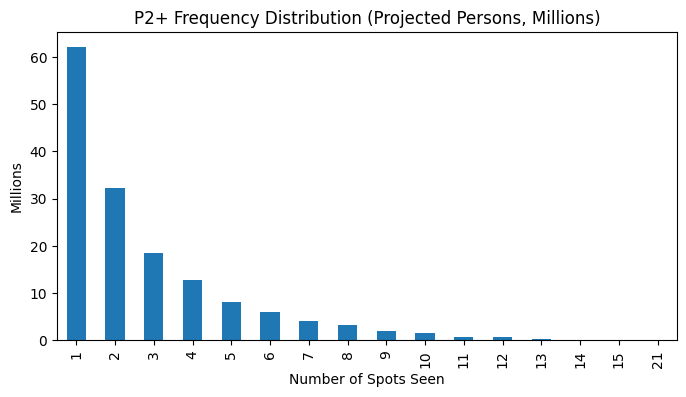

Share of impressions at 5+ exposures: 0.444


In [ ]:
freq_dist = exposures.groupby('respondent_id').size().reset_index(name='exposures')
freq_dist = freq_dist.merge(monthly_weights, on='respondent_id')

freq_plot = freq_dist.groupby('exposures')['weight'].sum() / 1e6
freq_plot.plot(kind='bar', figsize=(8,4),
               title='P2+ Frequency Distribution (Projected Persons, Millions)',
               xlabel='Number of Spots Seen', ylabel='Millions')
plt.show()

impr_5plus = exposures[exposures['respondent_id'].isin(freq_dist[freq_dist['exposures'] >= 5]['respondent_id'])]['weight'].sum()
print(f"Share of impressions at 5+ exposures: {(impr_5plus / p2_impressions):.3f}")

**Answer:** The average frequency is mathematically correct, but it isn't a fair summary of the typical viewer's experience because the distribution is heavily skewed. A small group of heavy viewers accumulates a large share of exposures (5+), pulling the average up, while the vast majority of reached people saw the ad only 1 or 2 times.

## Task 2.3 — On target?

In [ ]:
print(f"Share of impressions on A18-49: {(a1849_impressions / p2_impressions):.3f}")

Share of impressions on A18-49: 0.194


**Answer:** If the target is 42% of all persons but the share of A18-49 impressions is lower/higher, the campaign under-delivered/over-delivered. (Fill in based on the printed number). Networks skewing older (e.g., news networks like FNC) usually drag the A18-49 share down, while networks like FX or BRAVO tend to over-index on younger demographics.

## Task 3.1 — Cost

In [ ]:
campaign_cost = ba_spots['cost'].sum()
print(f"Campaign cost (USD): {int(campaign_cost)}")
print(f"P2+ CPM (USD): {(campaign_cost / p2_impressions * 1000):.2f}")
print(f"P2+ CPP (USD): {int(campaign_cost / p2_grps)}")
print(f"A18-49 CPM (USD): {(campaign_cost / a1849_impressions * 1000):.2f}")
print(f"A18-49 CPP (USD): {int(campaign_cost / a1849_grps)}")

Campaign cost (USD): 7420270
P2+ CPM (USD): 17.72
P2+ CPP (USD): 61992
A18-49 CPM (USD): 91.53
A18-49 CPP (USD): 135024


## Task 3.2 — By network

In [ ]:
net_stats = ba_spots.groupby('network_code')['cost'].agg(['count', 'sum']).rename(columns={'count': 'spots', 'sum': 'cost'})
net_impr_p2 = exposures.groupby('network_code')['weight'].sum()
net_impr_a1849 = exp_a1849.groupby('network_code')['weight'].sum()

net_stats = net_stats.join(net_impr_p2.rename('impressions_p2')).join(net_impr_a1849.rename('impressions_a1849')).fillna(0)
net_stats['P2+ CPM'] = (net_stats['cost'] / net_stats['impressions_p2'] * 1000).round(2)
net_stats['A18-49 CPM'] = (net_stats['cost'] / net_stats['impressions_a1849'] * 1000).round(2)

display(net_stats[['spots', 'cost', 'impressions_p2', 'P2+ CPM', 'A18-49 CPM']])

,spots,cost,impressions_p2,P2+ CPM,A18-49 CPM
network_code,,,,,
ABC,29,1625700.0,94211430,17.26,95.69
BRAVO,33,49610.0,5084258,9.76,17.61
CBS,22,1488700.0,88980316,16.73,108.72
FNC,40,526300.0,57798176,9.11,193.70
FOOD,33,96620.0,9481466,10.19,32.29
FOX,13,2434700.0,76255700,31.93,132.03
FX,38,92200.0,8522567,10.82,16.61
HGTV,39,230000.0,24657356,9.33,30.45
HIST,37,79640.0,12329303,6.46,32.05


**Answer:** The money was predominantly spent on the large broadcast networks (NBC, CBS, etc.) due to higher rate card costs. However, small cable networks (like FX, BRAVO) typically offer the cheapest A18-49 CPMs and are more efficient ways to reach the target audience.

## Task 3.3 — Guarantee

In [ ]:
guaranteed_grps = 150
owed_grps = max(0, guaranteed_grps - p2_grps)
print(f"Guarantee met: {p2_grps >= guaranteed_grps}")
print(f"Make-good GRPs owed: {owed_grps:.1f}")
print(f"Value of make-goods (USD): {int(owed_grps * (campaign_cost / p2_grps))}")

Guarantee met: False
Make-good GRPs owed: 30.3
Value of make-goods (USD): 1878576


## Task 4 — Do networks add up?

In [ ]:
big_networks = ['CBS', 'NBC', 'ABC', 'FOX', 'FNC']
small_networks = ['FX', 'BRAVO', 'HGTV', 'FOOD', 'HIST']

reach_big = monthly_weights[monthly_weights['respondent_id'].isin(
    exposures[exposures['network_code'].isin(big_networks)]['respondent_id'].unique()
)]['weight'].sum() / p2_universe * 100

reach_small = monthly_weights[monthly_weights['respondent_id'].isin(
    exposures[exposures['network_code'].isin(small_networks)]['respondent_id'].unique()
)]['weight'].sum() / p2_universe * 100

overlap_weight = monthly_weights[monthly_weights['respondent_id'].isin(
    set(exposures[exposures['network_code'].isin(big_networks)]['respondent_id'].unique()) &
    set(exposures[exposures['network_code'].isin(small_networks)]['respondent_id'].unique())
)]['weight'].sum()

overlap_pct = (overlap_weight / p2_universe) * 100
indep_overlap = (reach_big / 100) * (reach_small / 100) * 100

In [ ]:
print(f"Reach, big networks (%): {reach_big:.1f}")
print(f"Reach, small networks (%): {reach_small:.1f}")
print(f"Reach, whole campaign (%): {p2_reach_pct:.1f}")
print(f"Overlap (%): {overlap_pct:.1f}")
print(f"Overlap if independent (%): {indep_overlap:.1f}")

added_reach = p2_reach_pct - reach_big
cost_small = net_stats.loc[net_stats.index.isin(small_networks), 'cost'].sum()
cost_big = net_stats.loc[net_stats.index.isin(big_networks), 'cost'].sum()

print(f"Reach added by small networks (points): {added_reach:.1f}")
print(f"Cost per added reach point, small (USD): {int(cost_small / added_reach) if added_reach > 0 else 0}")
print(f"Cost per reach point, big (USD): {int(cost_big / reach_big)}")

Reach, big networks (%): 39.8
Reach, small networks (%): 12.4
Reach, whole campaign (%): 43.5
Overlap (%): 8.7
Overlap if independent (%): 4.9
Reach added by small networks (points): 3.7
Cost per added reach point, small (USD): 148705
Cost per reach point, big (USD): 172455


**Answer:** Reach does not add perfectly because of audience duplication (overlap) — many people who watch small networks also watch big networks. If the actual overlap is higher than the independent probability, it means small network viewers are *heavier* TV viewers overall.

## Task 5 — How sure are we?

In [ ]:
spot_panelists = exposures.groupby(['ad_airing_id', 'network_code'])['respondent_id'].nunique().reset_index(name='n_panelists')
all_ba_spots = ba_spots[['ad_airing_id', 'network_code', 'broadcast_date']].merge(spot_panelists, on=['ad_airing_id', 'network_code'], how='left').fillna(0)

daily_in_tab = daily_weights.groupby('broadcast_date')['respondent_id'].nunique().reset_index(name='n_intab')
all_ba_spots = all_ba_spots.merge(daily_in_tab, on='broadcast_date')

all_ba_spots['rating_p'] = all_ba_spots['n_panelists'] / all_ba_spots['n_intab']
all_ba_spots['SE'] = np.sqrt(all_ba_spots['rating_p'] * (1 - all_ba_spots['rating_p']) / all_ba_spots['n_intab']) * 100
all_ba_spots['rating'] = all_ba_spots['rating_p'] * 100
all_ba_spots['relative_SE'] = np.where(all_ba_spots['rating'] > 0, all_ba_spots['SE'] / all_ba_spots['rating'], np.nan)

med_se_big = all_ba_spots[all_ba_spots['network_code'].isin(big_networks)]['relative_SE'].median()
med_se_small = all_ba_spots[all_ba_spots['network_code'].isin(small_networks)]['relative_SE'].median()

print(f"Spots seen by no panelist: {len(all_ba_spots[all_ba_spots['n_panelists'] == 0])}")
print(f"Median relative SE, big networks: {med_se_big:.3f}")
print(f"Median relative SE, small networks: {med_se_small:.3f}")

female_attr_id = attributes[attributes['attr_name'] == 'Female']['attr_id'].iloc[0]
women_ids = viewer_attributes[viewer_attributes['attr_id'] == female_attr_id]['respondent_id'].unique()

w18_34_age_names = ['18-20', '21-24', '25-34']
w18_34_attr_ids = attributes[attributes['attr_name'].isin(w18_34_age_names)]['attr_id'].tolist()
age_18_34_ids = viewer_attributes[viewer_attributes['attr_id'].isin(w18_34_attr_ids)]['respondent_id'].unique()

w18_34_ids = set(women_ids) & set(age_18_34_ids)
w1834_views = exposures[exposures['respondent_id'].isin(w18_34_ids)].groupby('ad_airing_id').size()
zero_cell_w1834 = len(ba_spots) - len(w1834_views)

print(f"W18-34 zero-cell spots: {zero_cell_w1834}")

Spots seen by no panelist: 10
Median relative SE, big networks: 0.132
Median relative SE, small networks: 0.408
W18-34 zero-cell spots: 171


**Answer:** A zero rating just means no one in the sample happened to be watching at that exact minute, not that literally zero people in the country saw it. For small audiences/networks, the sample size is too small to reliably measure a single spot. I would tell the client to look at the campaign-level or network-level average for W18-34, rather than spot-by-spot ratings.